# Robust Autonomous Navigation and Control of a Differential-Drive Robot Under Uncertain Perception

## Engineering Investigation

**Research question:**  
How does imperfect state information affect the navigation performance of an autonomous differential-drive robot, and how can feedback control improve its robustness?

### Objective
This notebook builds a reproducible, simulation-based mobile-robot system using:

- A* path planning
- obstacle inflation for robot-body clearance
- differential-drive kinematics
- continuous trajectory generation
- proportional (P) and PID feedback control
- controlled state-estimation uncertainty
- repeated Monte Carlo experiments
- quantitative navigation metrics
- an engineering comparison of controller behavior

**Engineering workflow:** design → simulate → test → identify limitation → improve → retest.

No hardware, external dataset, deep learning, ROS, or paid software is required.


In [ ]:
# ============================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from heapq import heappush, heappop

np.random.seed(42)

print("Environment ready.")


Environment ready.


In [ ]:
# ============================================
# 2. ROBOT PARAMETERS
# ============================================

WHEEL_RADIUS = 0.05
WHEEL_BASE = 0.20

MAX_LINEAR_VELOCITY = 0.50
MAX_ANGULAR_VELOCITY = 2.0

DT = 0.05
ROBOT_RADIUS = 0.10

print("Robot parameters initialized.")
print(f"Wheel radius: {WHEEL_RADIUS} m")
print(f"Wheel separation: {WHEEL_BASE} m")
print(f"Maximum linear velocity: {MAX_LINEAR_VELOCITY} m/s")
print(f"Maximum angular velocity: {MAX_ANGULAR_VELOCITY} rad/s")
print(f"Robot radius: {ROBOT_RADIUS} m")
print(f"Simulation time step: {DT} s")


Robot parameters initialized.
Wheel radius: 0.05 m
Wheel separation: 0.2 m
Maximum linear velocity: 0.5 m/s
Maximum angular velocity: 2.0 rad/s
Robot radius: 0.1 m
Simulation time step: 0.05 s


In [ ]:
# ============================================
# 3. DIFFERENTIAL-DRIVE KINEMATIC MODEL
# ============================================

def normalize_angle(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi


def differential_drive_model(state, v, omega, dt=DT):
    """Update [x, y, theta] using differential-drive kinematics."""

    x, y, theta = state

    v = np.clip(v, -MAX_LINEAR_VELOCITY, MAX_LINEAR_VELOCITY)
    omega = np.clip(omega, -MAX_ANGULAR_VELOCITY, MAX_ANGULAR_VELOCITY)

    x_new = x + v * np.cos(theta) * dt
    y_new = y + v * np.sin(theta) * dt
    theta_new = normalize_angle(theta + omega * dt)

    return np.array([x_new, y_new, theta_new])


def wheel_to_robot_velocity(v_left, v_right):
    """Convert left/right wheel linear velocities to v and omega."""

    v = (v_right + v_left) / 2.0
    omega = (v_right - v_left) / WHEEL_BASE

    return v, omega

print("Robot model functions initialized.")


Robot model functions initialized.


In [ ]:
# ============================================
# 4. ROBOT-MODEL VALIDATION
# ============================================

# Straight-line test
state = np.array([0.0, 0.0, 0.0])

for _ in range(100):
    state = differential_drive_model(state, 0.3, 0.0)

straight_distance = np.linalg.norm(state[:2])

# Constant-turn test
turn_state = np.array([0.0, 0.0, 0.0])

for _ in range(200):
    turn_state = differential_drive_model(turn_state, 0.3, 0.8)

theoretical_radius = 0.3 / 0.8
measured_radius = np.hypot(
    turn_state[0],
    turn_state[1] - theoretical_radius
)

v_test, omega_test = wheel_to_robot_velocity(0.2, 0.4)

print(f"Straight-line distance after 5 s: {straight_distance:.3f} m")
print(f"Theoretical turning radius: {theoretical_radius:.3f} m")
print(f"Measured turning-radius consistency check: {measured_radius:.3f} m")
print(f"Wheel test -> v={v_test:.3f} m/s, omega={omega_test:.3f} rad/s")

assert abs(straight_distance - 1.5) < 1e-9
assert abs(v_test - 0.3) < 1e-9
assert abs(omega_test - 1.0) < 1e-9

print("Robot-model validation passed.")


Straight-line distance after 5 s: 1.500 m
Theoretical turning radius: 0.375 m
Measured turning-radius consistency check: 0.382 m
Wheel test -> v=0.300 m/s, omega=1.000 rad/s
Robot-model validation passed.


## 5. Environment and A* Planning

The robot operates in a 4 m × 4 m occupancy grid. Obstacles are rectangular regions defined directly in grid coordinates.

The planner uses 8-connectivity and an Euclidean heuristic.


In [ ]:
# ============================================
# 5. ENVIRONMENT
# ============================================

GRID_SIZE = 40
GRID_RESOLUTION = 0.10

grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)


def add_rectangle_obstacle(grid, x_min, x_max, y_min, y_max):
    grid[y_min:y_max + 1, x_min:x_max + 1] = 1


# Original obstacle definitions from the project
OBSTACLE_DEFINITIONS = [
    (8, 12, 5, 28),
    (18, 22, 12, 35),
    (28, 32, 4, 25),
]

for obstacle in OBSTACLE_DEFINITIONS:
    add_rectangle_obstacle(grid, *obstacle)

START = (2, 2)
GOAL = (37, 37)

print(f"Grid size: {GRID_SIZE} x {GRID_SIZE}")
print(f"Environment: {GRID_SIZE * GRID_RESOLUTION:.1f} m x {GRID_SIZE * GRID_RESOLUTION:.1f} m")
print(f"Obstacle cells: {np.sum(grid == 1)}")
print(f"Start: {START}")
print(f"Goal: {GOAL}")


Grid size: 40 x 40
Environment: 4.0 m x 4.0 m
Obstacle cells: 350
Start: (2, 2)
Goal: (37, 37)


In [ ]:
# ============================================
# 6. A* PATH PLANNER
# ============================================

def heuristic(a, b):
    return np.hypot(a[0] - b[0], a[1] - b[1])


def get_neighbors(node, occupancy_grid):
    x, y = node

    directions = [
        (-1, 0), (1, 0), (0, -1), (0, 1),
        (-1, -1), (-1, 1), (1, -1), (1, 1)
    ]

    neighbors = []

    for dx, dy in directions:
        nx, ny = x + dx, y + dy

        if not (0 <= nx < occupancy_grid.shape[1]):
            continue
        if not (0 <= ny < occupancy_grid.shape[0]):
            continue
        if occupancy_grid[ny, nx] == 1:
            continue

        neighbors.append((nx, ny))

    return neighbors


def astar(occupancy_grid, start, goal):
    """A* path planning on a 2-D occupancy grid."""

    if occupancy_grid[start[1], start[0]] == 1:
        return None
    if occupancy_grid[goal[1], goal[0]] == 1:
        return None

    open_set = []
    heappush(open_set, (heuristic(start, goal), start))

    came_from = {}
    g_cost = {start: 0.0}

    while open_set:
        _, current = heappop(open_set)

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            path.reverse()
            return path

        for neighbor in get_neighbors(current, occupancy_grid):
            dx = neighbor[0] - current[0]
            dy = neighbor[1] - current[1]

            tentative_g = g_cost[current] + np.hypot(dx, dy)

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                f_cost = tentative_g + heuristic(neighbor, goal)
                heappush(open_set, (f_cost, neighbor))

    return None


original_path = astar(grid, START, GOAL)

assert original_path is not None
print(f"Original A* path found: {len(original_path)} grid points")


Original A* path found: 47 grid points


In [ ]:
# ============================================
# 7. SAFETY-AWARE OBSTACLE INFLATION
# ============================================

def inflate_obstacles(occupancy_grid, robot_radius, resolution):
    """Inflate occupied cells so the robot center avoids the body-clearance zone."""

    inflation_cells = int(np.ceil(robot_radius / resolution))
    inflated = occupancy_grid.copy()

    obstacle_positions = np.argwhere(occupancy_grid == 1)

    for y, x in obstacle_positions:
        y_min = max(0, y - inflation_cells)
        y_max = min(occupancy_grid.shape[0] - 1, y + inflation_cells)
        x_min = max(0, x - inflation_cells)
        x_max = min(occupancy_grid.shape[1] - 1, x + inflation_cells)

        inflated[y_min:y_max + 1, x_min:x_max + 1] = 1

    return inflated


safe_grid = inflate_obstacles(
    grid,
    ROBOT_RADIUS,
    GRID_RESOLUTION
)

safe_path = astar(safe_grid, START, GOAL)

assert safe_path is not None

print(f"Original obstacle cells: {np.sum(grid == 1)}")
print(f"Inflated obstacle cells: {np.sum(safe_grid == 1)}")
print(f"Safe A* path points: {len(safe_path)}")


Original obstacle cells: 350
Inflated obstacle cells: 532
Safe A* path points: 49


In [ ]:
# ============================================
# 8. PATH SIMPLIFICATION AND WORLD COORDINATES
# ============================================

def simplify_path(path):
    """Keep only points where the discrete travel direction changes."""

    if len(path) <= 2:
        return path

    simplified = [path[0]]
    previous_direction = None

    for i in range(1, len(path)):
        dx = path[i][0] - path[i - 1][0]
        dy = path[i][1] - path[i - 1][1]

        direction = (int(np.sign(dx)), int(np.sign(dy)))

        if previous_direction is not None and direction != previous_direction:
            simplified.append(path[i - 1])

        previous_direction = direction

    simplified.append(path[-1])
    return simplified


def grid_to_world(path, resolution):
    return np.array([[x * resolution, y * resolution] for x, y in path], dtype=float)


waypoints_grid = simplify_path(safe_path)
waypoints_world = grid_to_world(waypoints_grid, GRID_RESOLUTION)

print(f"Safe A* points: {len(safe_path)}")
print(f"Simplified waypoints: {len(waypoints_grid)}")
print("World-coordinate waypoints:")
print(np.round(waypoints_world, 3))


Safe A* points: 49
Simplified waypoints: 10
World-coordinate waypoints:
[[0.2 0.2]
 [0.3 0.3]
 [1.3 0.3]
 [2.  1. ]
 [2.3 1. ]
 [2.4 1.1]
 [2.4 1.8]
 [2.6 2. ]
 [2.6 2.6]
 [3.7 3.7]]


In [ ]:
# ============================================
# 9. WAYPOINT HEADINGS AND REFERENCE TRAJECTORY
# ============================================

def calculate_headings(waypoints):
    headings = []

    for i in range(len(waypoints)):
        if i == len(waypoints) - 1:
            delta = waypoints[i] - waypoints[i - 1]
        else:
            delta = waypoints[i + 1] - waypoints[i]

        headings.append(np.arctan2(delta[1], delta[0]))

    return np.array(headings)


TRAJECTORY_SPACING = 0.05


def generate_reference_trajectory(waypoints, spacing=TRAJECTORY_SPACING):
    positions = []
    headings = []

    for i in range(len(waypoints) - 1):
        start = np.asarray(waypoints[i], dtype=float)
        end = np.asarray(waypoints[i + 1], dtype=float)

        segment = end - start
        length = np.linalg.norm(segment)

        if length == 0:
            continue

        heading = np.arctan2(segment[1], segment[0])
        n_samples = max(2, int(np.ceil(length / spacing)))

        for j in range(n_samples):
            fraction = j / (n_samples - 1)
            positions.append(start + fraction * segment)
            headings.append(heading)

    positions.append(np.asarray(waypoints[-1], dtype=float))

    final_segment = np.asarray(waypoints[-1]) - np.asarray(waypoints[-2])
    headings.append(np.arctan2(final_segment[1], final_segment[0]))

    return np.array(positions), np.array(headings)


waypoint_headings = calculate_headings(waypoints_world)
reference_positions, reference_headings = generate_reference_trajectory(waypoints_world)

print(f"Reference states: {len(reference_positions)}")
print(f"Initial heading: {np.degrees(reference_headings[0]):.2f} deg")
print(f"Final heading: {np.degrees(reference_headings[-1]):.2f} deg")


Reference states: 119
Initial heading: 45.00 deg
Final heading: 45.00 deg


In [ ]:
# ============================================
# 10. COLLISION / SAFETY HELPERS
# ============================================

def world_to_grid(x, y, resolution=GRID_RESOLUTION):
    return int(np.floor(x / resolution)), int(np.floor(y / resolution))


def check_collision(trajectory, occupancy_grid):
    """Discrete center-cell collision check."""

    collisions = []

    for i, state in enumerate(trajectory):
        gx, gy = world_to_grid(state[0], state[1])

        if 0 <= gx < occupancy_grid.shape[1] and 0 <= gy < occupancy_grid.shape[0]:
            if occupancy_grid[gy, gx] == 1:
                collisions.append(i)

    return collisions


reference_safety_violations = check_collision(reference_positions, safe_grid)

print("Reference trajectory safety violation:", bool(reference_safety_violations))
print("Reference safety-violation states:", len(reference_safety_violations))


Reference trajectory safety violation: False
Reference safety-violation states: 0


In [ ]:
# ============================================
# 11. P-CONTROLLER AND LOOK-AHEAD
# ============================================

LOOKAHEAD_DISTANCE = 0.15

def find_lookahead_reference(state, reference_positions):
    position = state[:2]
    distances = np.linalg.norm(reference_positions - position, axis=1)
    nearest_index = int(np.argmin(distances))

    cumulative_distance = 0.0

    for i in range(nearest_index, len(reference_positions) - 1):
        segment = reference_positions[i + 1] - reference_positions[i]
        segment_length = np.linalg.norm(segment)
        cumulative_distance += segment_length

        if cumulative_distance >= LOOKAHEAD_DISTANCE:
            return i + 1, reference_positions[i + 1]

    return len(reference_positions) - 1, reference_positions[-1]


K_LINEAR = 1.0
K_ANGULAR = 3.0


def proportional_controller(state, target_position):
    x, y, theta = state
    dx = target_position[0] - x
    dy = target_position[1] - y

    distance_error = np.hypot(dx, dy)
    desired_direction = np.arctan2(dy, dx)
    heading_error = normalize_angle(desired_direction - theta)

    v = np.clip(K_LINEAR * distance_error, -MAX_LINEAR_VELOCITY, MAX_LINEAR_VELOCITY)
    omega = np.clip(K_ANGULAR * heading_error, -MAX_ANGULAR_VELOCITY, MAX_ANGULAR_VELOCITY)

    return v, omega, distance_error, heading_error

print("P controller initialized.")


P controller initialized.


In [ ]:
# ============================================
# 12. GENERIC NAVIGATION SIMULATOR
# ============================================

def simulate_controller(
    controller_name,
    initial_state,
    reference_positions,
    reference_headings,
    max_steps=2000,
    goal_tolerance=0.05,
    position_noise_std=0.0,
    heading_noise_std=0.0,
    rng=None
):
    """Run a controller using noisy state estimates for feedback.

    The robot state itself remains the true simulated state.
    Noise is applied only to the controller's estimated state.
    """

    if rng is None:
        rng = np.random.default_rng(42)

    true_state = np.array(initial_state, dtype=float)
    trajectory = [true_state.copy()]

    linear_commands = []
    angular_commands = []
    distance_errors = []
    heading_errors = []

    for step in range(max_steps):

        estimated_state = true_state.copy()

        if position_noise_std > 0:
            estimated_state[:2] += rng.normal(0, position_noise_std, 2)

        if heading_noise_std > 0:
            estimated_state[2] = normalize_angle(
                estimated_state[2] + rng.normal(0, heading_noise_std)
            )

        target_index, target_position = find_lookahead_reference(
            estimated_state,
            reference_positions
        )

        if controller_name == "P":
            v, omega, distance_error, heading_error = proportional_controller(
                estimated_state,
                target_position
            )

        elif controller_name == "PID":
            raise ValueError("Use simulate_pid_controller for PID state.")

        else:
            raise ValueError("Unknown controller.")

        true_state = differential_drive_model(true_state, v, omega)

        trajectory.append(true_state.copy())
        linear_commands.append(v)
        angular_commands.append(omega)
        distance_errors.append(distance_error)
        heading_errors.append(heading_error)

        goal_distance = np.linalg.norm(
            true_state[:2] - reference_positions[-1]
        )

        if goal_distance <= goal_tolerance:
            break

    return {
        "trajectory": np.array(trajectory),
        "linear_commands": np.array(linear_commands),
        "angular_commands": np.array(angular_commands),
        "distance_errors": np.array(distance_errors),
        "heading_errors": np.array(heading_errors),
        "reached_goal": goal_distance <= goal_tolerance,
        "goal_distance": goal_distance,
    }


def compute_navigation_metrics(result, reference_positions):
    trajectory = result["trajectory"]

    position_errors = np.array([
        np.min(np.linalg.norm(reference_positions - p, axis=1))
        for p in trajectory[:, :2]
    ])

    path_length = np.sum(
        np.linalg.norm(np.diff(trajectory[:, :2], axis=0), axis=1)
    )

    navigation_time = (len(trajectory) - 1) * DT

    linear_effort = np.sum(result["linear_commands"] ** 2) * DT
    angular_effort = np.sum(result["angular_commands"] ** 2) * DT

    return {
        "mean_tracking_error_m": np.mean(position_errors),
        "rmse_tracking_error_m": np.sqrt(np.mean(position_errors ** 2)),
        "max_tracking_error_m": np.max(position_errors),
        "final_position_error_m": result["goal_distance"],
        "path_length_m": path_length,
        "navigation_time_s": navigation_time,
        "linear_control_effort": linear_effort,
        "angular_control_effort": angular_effort,
        "total_control_effort": linear_effort + angular_effort,
        "safety_violation_states": len(
            check_collision(trajectory, safe_grid)
        ),
        "goal_reached": result["reached_goal"],
    }

print("Navigation simulation utilities initialized.")


Navigation simulation utilities initialized.


In [ ]:
# ============================================
# 13. BASELINE P-CONTROL SIMULATION
# ============================================

initial_state = np.array([
    reference_positions[0, 0],
    reference_positions[0, 1],
    reference_headings[0]
])

p_result = simulate_controller(
    "P",
    initial_state,
    reference_positions,
    reference_headings,
    position_noise_std=0.0,
    heading_noise_std=0.0,
    rng=np.random.default_rng(42)
)

p_metrics = compute_navigation_metrics(p_result, reference_positions)

print("========== BASELINE P-CONTROLLER ==========")
for key, value in p_metrics.items():
    print(f"{key}: {value}")


========== BASELINE P-CONTROLLER ==========
mean_tracking_error_m: 0.015703128836059215
rmse_tracking_error_m: 0.018046331371914817
max_tracking_error_m: 0.04421658443330794
final_position_error_m: 0.049768486829126254
path_length_m: 5.5248683441918836
navigation_time_s: 35.75
linear_control_effort: 0.8731525791173098
angular_control_effort: 3.0297514505840395
total_control_effort: 3.9029040297013493
safety_violation_states: 24
goal_reached: True


In [ ]:
# ============================================
# 14. PID CONTROLLER
# ============================================

KP_LINEAR = 1.0
KI_LINEAR = 0.05
KD_LINEAR = 0.10

KP_ANGULAR = 3.0
KI_ANGULAR = 0.05
KD_ANGULAR = 0.10


def simulate_pid_controller(
    initial_state,
    reference_positions,
    reference_headings,
    max_steps=2000,
    goal_tolerance=0.05,
    position_noise_std=0.0,
    heading_noise_std=0.0,
    rng=None
):
    if rng is None:
        rng = np.random.default_rng(42)

    true_state = np.array(initial_state, dtype=float)
    trajectory = [true_state.copy()]

    linear_commands = []
    angular_commands = []
    distance_errors = []
    heading_errors = []

    previous_distance_error = 0.0
    previous_heading_error = 0.0
    distance_integral = 0.0
    heading_integral = 0.0

    for step in range(max_steps):

        estimated_state = true_state.copy()

        if position_noise_std > 0:
            estimated_state[:2] += rng.normal(0, position_noise_std, 2)

        if heading_noise_std > 0:
            estimated_state[2] = normalize_angle(
                estimated_state[2] + rng.normal(0, heading_noise_std)
            )

        target_index, target_position = find_lookahead_reference(
            estimated_state,
            reference_positions
        )

        dx = target_position[0] - estimated_state[0]
        dy = target_position[1] - estimated_state[1]

        distance_error = np.hypot(dx, dy)
        desired_direction = np.arctan2(dy, dx)
        heading_error = normalize_angle(
            desired_direction - estimated_state[2]
        )

        distance_integral += distance_error * DT
        heading_integral += heading_error * DT

        distance_derivative = (
            distance_error - previous_distance_error
        ) / DT

        heading_derivative = (
            heading_error - previous_heading_error
        ) / DT

        v = (
            KP_LINEAR * distance_error
            + KI_LINEAR * distance_integral
            + KD_LINEAR * distance_derivative
        )

        omega = (
            KP_ANGULAR * heading_error
            + KI_ANGULAR * heading_integral
            + KD_ANGULAR * heading_derivative
        )

        v = np.clip(v, -MAX_LINEAR_VELOCITY, MAX_LINEAR_VELOCITY)
        omega = np.clip(omega, -MAX_ANGULAR_VELOCITY, MAX_ANGULAR_VELOCITY)

        true_state = differential_drive_model(true_state, v, omega)

        trajectory.append(true_state.copy())
        linear_commands.append(v)
        angular_commands.append(omega)
        distance_errors.append(distance_error)
        heading_errors.append(heading_error)

        previous_distance_error = distance_error
        previous_heading_error = heading_error

        goal_distance = np.linalg.norm(
            true_state[:2] - reference_positions[-1]
        )

        if goal_distance <= goal_tolerance:
            break

    return {
        "trajectory": np.array(trajectory),
        "linear_commands": np.array(linear_commands),
        "angular_commands": np.array(angular_commands),
        "distance_errors": np.array(distance_errors),
        "heading_errors": np.array(heading_errors),
        "reached_goal": goal_distance <= goal_tolerance,
        "goal_distance": goal_distance,
    }

print("PID controller initialized.")


PID controller initialized.


In [ ]:
# ============================================
# 15. PID SIMULATION
# ============================================

pid_result = simulate_pid_controller(
    initial_state,
    reference_positions,
    reference_headings,
    position_noise_std=0.0,
    heading_noise_std=0.0,
    rng=np.random.default_rng(42)
)

pid_metrics = compute_navigation_metrics(pid_result, reference_positions)

print("========== PID CONTROLLER ==========")
for key, value in pid_metrics.items():
    print(f"{key}: {value}")


========== PID CONTROLLER ==========
mean_tracking_error_m: 0.01683601149522124
rmse_tracking_error_m: 0.019026554803027982
max_tracking_error_m: 0.04452072218347804
final_position_error_m: 0.041092936016299056
path_length_m: 5.56746139785045
navigation_time_s: 22.8
linear_control_effort: 1.5043933943576115
angular_control_effort: 5.005576920510663
total_control_effort: 6.509970314868275
safety_violation_states: 11
goal_reached: True


In [ ]:
# ============================================
# 16. P VS PID: PERFECT-STATE COMPARISON
# ============================================

comparison = pd.DataFrame(
    [p_metrics, pid_metrics],
    index=["P controller", "PID controller"]
)

comparison = comparison[
    [
        "mean_tracking_error_m",
        "rmse_tracking_error_m",
        "max_tracking_error_m",
        "final_position_error_m",
        "path_length_m",
        "navigation_time_s",
        "total_control_effort",
        "safety_violation_states",
        "goal_reached",
    ]
]

display(comparison.round(5))


,mean_tracking_error_m,rmse_tracking_error_m,max_tracking_error_m,final_position_error_m,path_length_m,navigation_time_s,total_control_effort,safety_violation_states,goal_reached
P controller,0.01570,0.01805,0.04422,0.04977,5.52487,35.75,3.90290,24,True
PID controller,0.01684,0.01903,0.04452,0.04109,5.56746,22.80,6.50997,11,True


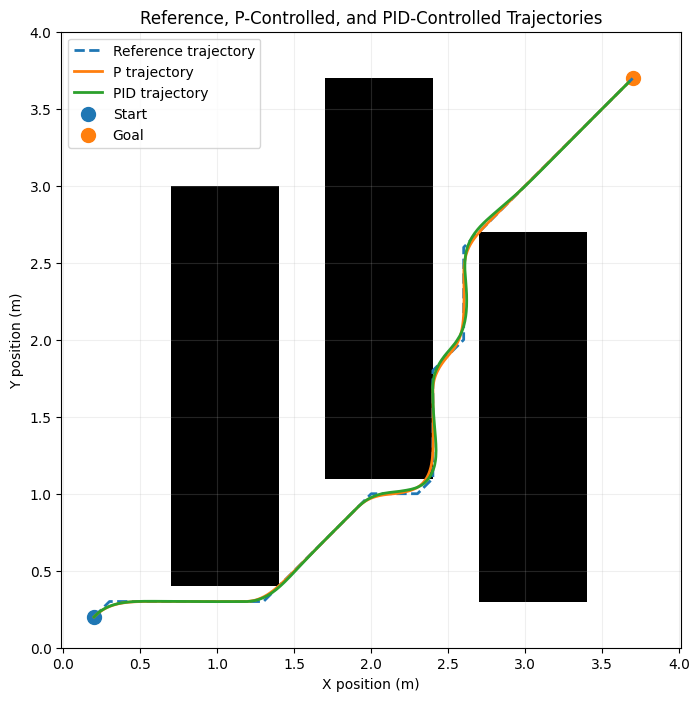

In [ ]:
# ============================================
# 17. TRAJECTORY VISUALIZATION
# ============================================

plt.figure(figsize=(8, 8))

plt.imshow(
    safe_grid,
    origin="lower",
    cmap="Greys",
    extent=[
        0,
        GRID_SIZE * GRID_RESOLUTION,
        0,
        GRID_SIZE * GRID_RESOLUTION
    ]
)

plt.plot(
    reference_positions[:, 0],
    reference_positions[:, 1],
    "--",
    linewidth=2,
    label="Reference trajectory"
)

plt.plot(
    p_result["trajectory"][:, 0],
    p_result["trajectory"][:, 1],
    linewidth=2,
    label="P trajectory"
)

plt.plot(
    pid_result["trajectory"][:, 0],
    pid_result["trajectory"][:, 1],
    linewidth=2,
    label="PID trajectory"
)

plt.scatter(
    reference_positions[0, 0],
    reference_positions[0, 1],
    s=100,
    label="Start"
)

plt.scatter(
    reference_positions[-1, 0],
    reference_positions[-1, 1],
    s=100,
    label="Goal"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Reference, P-Controlled, and PID-Controlled Trajectories")
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


In [ ]:
# ============================================
# 18. EXACT CONTINUOUS CIRCLE-RECTANGLE CHECK
# ============================================

def point_to_rectangle_distance(
    point_x,
    point_y,
    rect_x_min,
    rect_x_max,
    rect_y_min,
    rect_y_max
):
    dx = max(rect_x_min - point_x, 0, point_x - rect_x_max)
    dy = max(rect_y_min - point_y, 0, point_y - rect_y_max)
    return np.hypot(dx, dy)


def check_physical_collision(
    trajectory,
    obstacle_definitions,
    robot_radius=ROBOT_RADIUS,
    resolution=GRID_RESOLUTION
):
    """Continuous circle-vs-rectangle check using the actual grid definitions.

    A grid rectangle covering cells x_min..x_max and y_min..y_max
    occupies the continuous region:
        [x_min*resolution, (x_max+1)*resolution]
        [y_min*resolution, (y_max+1)*resolution]
    """

    collision_indices = []

    world_rectangles = [
        (
            x_min * resolution,
            (x_max + 1) * resolution,
            y_min * resolution,
            (y_max + 1) * resolution
        )
        for x_min, x_max, y_min, y_max in obstacle_definitions
    ]

    for i, state in enumerate(trajectory):
        x, y = state[:2]

        for x_min, x_max, y_min, y_max in world_rectangles:
            distance = point_to_rectangle_distance(
                x, y,
                x_min, x_max,
                y_min, y_max
            )

            if distance < robot_radius:
                collision_indices.append(i)
                break

    return collision_indices


p_physical_collisions = check_physical_collision(
    p_result["trajectory"],
    OBSTACLE_DEFINITIONS
)

pid_physical_collisions = check_physical_collision(
    pid_result["trajectory"],
    OBSTACLE_DEFINITIONS
)

print("P physical collision states:", len(p_physical_collisions))
print("PID physical collision states:", len(pid_physical_collisions))


P physical collision states: 18
PID physical collision states: 7


## 19. Controlled State-Estimation Uncertainty

The true robot state is kept separate from the controller's estimated state.

At each control step, zero-mean Gaussian error is added to the estimated position and heading only. The robot dynamics continue to use the true state.

This isolates the effect of imperfect perception/state estimation from the physical motion model.


In [ ]:
# ============================================
# 19. UNCERTAINTY EXPERIMENT SETTINGS
# ============================================

POSITION_NOISE_LEVELS = [0.00, 0.01, 0.02, 0.03, 0.05]
HEADING_NOISE_STD = np.radians(2.0)
MONTE_CARLO_TRIALS = 20

print("Position-noise levels (m):", POSITION_NOISE_LEVELS)
print("Heading-noise standard deviation (deg):", np.degrees(HEADING_NOISE_STD))
print("Monte Carlo trials per condition:", MONTE_CARLO_TRIALS)


Position-noise levels (m): [0.0, 0.01, 0.02, 0.03, 0.05]
Heading-noise standard deviation (deg): 2.0
Monte Carlo trials per condition: 20


In [ ]:
# ============================================
# 20. MONTE CARLO UNCERTAINTY EXPERIMENT
# ============================================

records = []

for controller in ["P", "PID"]:

    for noise_std in POSITION_NOISE_LEVELS:

        for trial in range(MONTE_CARLO_TRIALS):

            rng = np.random.default_rng(
                1000 + trial
            )

            if controller == "P":
                result = simulate_controller(
                    "P",
                    initial_state,
                    reference_positions,
                    reference_headings,
                    position_noise_std=noise_std,
                    heading_noise_std=HEADING_NOISE_STD,
                    rng=rng
                )

            else:
                result = simulate_pid_controller(
                    initial_state,
                    reference_positions,
                    reference_headings,
                    position_noise_std=noise_std,
                    heading_noise_std=HEADING_NOISE_STD,
                    rng=rng
                )

            metrics = compute_navigation_metrics(
                result,
                reference_positions
            )

            records.append({
                "controller": controller,
                "position_noise_std_m": noise_std,
                "trial": trial + 1,
                **metrics
            })

uncertainty_results = pd.DataFrame(records)

print("Experiment complete.")
print("Total simulation runs:", len(uncertainty_results))


Experiment complete.
Total simulation runs: 200


In [ ]:
# ============================================
# 21. UNCERTAINTY RESULTS SUMMARY
# ============================================

uncertainty_summary = (
    uncertainty_results
    .groupby(["controller", "position_noise_std_m"])
    .agg(
        mean_tracking_error_m=("mean_tracking_error_m", "mean"),
        rmse_tracking_error_m=("rmse_tracking_error_m", "mean"),
        final_position_error_m=("final_position_error_m", "mean"),
        navigation_time_s=("navigation_time_s", "mean"),
        safety_violation_states=("safety_violation_states", "mean"),
        success_rate=("goal_reached", "mean"),
    )
    .reset_index()
)

display(uncertainty_summary.round(5))


,controller,position_noise_std_m,mean_tracking_error_m,rmse_tracking_error_m,final_position_error_m,navigation_time_s,safety_violation_states,success_rate
0,P,0.00,0.01572,0.01803,0.04978,35.7775,34.20,1.0
1,P,0.01,0.01571,0.01796,0.04864,35.4975,35.35,1.0
2,P,0.02,0.01597,0.01815,0.04845,35.2725,36.65,1.0
3,P,0.03,0.01644,0.01853,0.04854,34.8925,37.30,1.0
4,P,0.05,0.01779,0.01984,0.04804,33.7650,26.70,1.0
5,PID,0.00,0.01688,0.01906,0.04129,22.7850,11.55,1.0
6,PID,0.01,0.01696,0.01896,0.04440,22.6025,11.90,1.0
7,PID,0.02,0.01776,0.01980,0.04343,22.4600,11.80,1.0
8,PID,0.03,0.01923,0.02151,0.04392,22.3025,11.10,1.0
9,PID,0.05,0.02443,0.02830,0.04172,21.8725,10.75,1.0


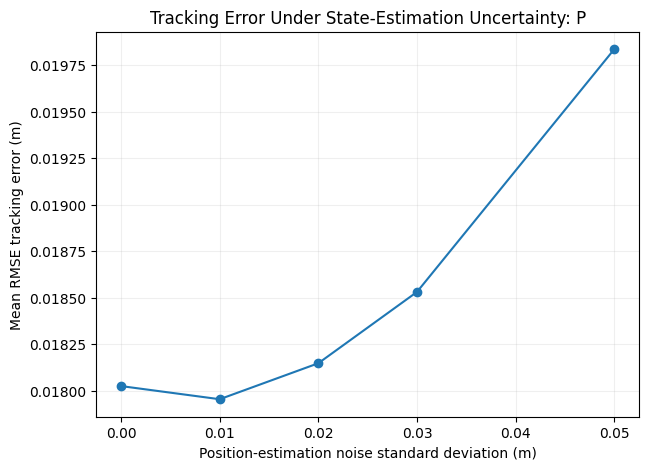

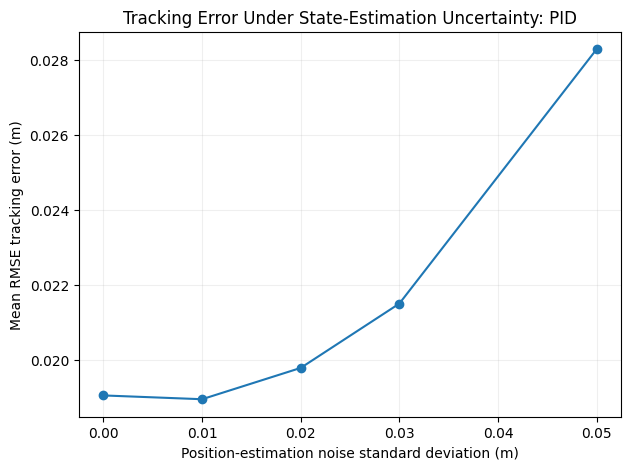

In [ ]:
# ============================================
# 22. UNCERTAINTY VISUALIZATION
# ============================================

for controller in ["P", "PID"]:
    subset = uncertainty_summary[
        uncertainty_summary["controller"] == controller
    ]

    plt.figure(figsize=(7, 5))

    plt.plot(
        subset["position_noise_std_m"],
        subset["rmse_tracking_error_m"],
        marker="o"
    )

    plt.xlabel("Position-estimation noise standard deviation (m)")
    plt.ylabel("Mean RMSE tracking error (m)")
    plt.title(f"Tracking Error Under State-Estimation Uncertainty: {controller}")
    plt.grid(True, alpha=0.2)
    plt.show()


In [ ]:
# ============================================
# 23. FAILURE-MODE DIAGNOSTICS
# ============================================

print("========== BASELINE FAILURE-MODE DIAGNOSTICS ==========")

p_safe = len(
    check_collision(p_result["trajectory"], safe_grid)
)

pid_safe = len(
    check_collision(pid_result["trajectory"], safe_grid)
)

print(f"P safety-violation states:   {p_safe}")
print(f"PID safety-violation states: {pid_safe}")

print()
print("Reference trajectory safety violations:",
      len(reference_safety_violations))

print()
print("Interpretation:")
print(
    "The reference trajectory is safe on the inflated grid, "
    "while controller trajectories can deviate from that safe reference."
)
print(
    "Therefore, path planning safety alone does not guarantee "
    "closed-loop tracking safety."
)


========== BASELINE FAILURE-MODE DIAGNOSTICS ==========
P safety-violation states:   24
PID safety-violation states: 11

Reference trajectory safety violations: 0

Interpretation:
The reference trajectory is safe on the inflated grid, while controller trajectories can deviate from that safe reference.
Therefore, path planning safety alone does not guarantee closed-loop tracking safety.


In [ ]:
# ============================================
# 24. REFERENCE-PATH CLEARANCE DIAGNOSTIC
# ============================================

def distance_point_to_rectangles(point, obstacle_definitions):
    x, y = point
    distances = []

    for x_min, x_max, y_min, y_max in obstacle_definitions:
        rx_min = x_min * GRID_RESOLUTION
        rx_max = (x_max + 1) * GRID_RESOLUTION
        ry_min = y_min * GRID_RESOLUTION
        ry_max = (y_max + 1) * GRID_RESOLUTION

        distances.append(
            point_to_rectangle_distance(
                x, y, rx_min, rx_max, ry_min, ry_max
            )
        )

    return min(distances)

reference_clearances = np.array([
    distance_point_to_rectangles(p, OBSTACLE_DEFINITIONS)
    for p in reference_positions
])

reference_physical_collisions = check_physical_collision(
    np.column_stack((reference_positions, reference_headings)),
    OBSTACLE_DEFINITIONS
)

print(f"Minimum geometric distance from reference center to obstacle: {reference_clearances.min():.4f} m")
print(f"Minimum clearance after subtracting robot radius: {max(0.0, reference_clearances.min() - ROBOT_RADIUS):.4f} m")
print(f"Reference physical collision states (strict distance < radius): {len(reference_physical_collisions)}")
print(f"Mean geometric clearance: {reference_clearances.mean():.4f} m")


Minimum geometric distance from reference center to obstacle: 0.1000 m
Minimum clearance after subtracting robot radius: 0.0000 m
Reference physical collision states (strict distance < radius): 0
Mean geometric clearance: 0.3307 m


In [ ]:
# ============================================
# 25. FINAL CONTROLLER COMPARISON
# ============================================

final_comparison = pd.DataFrame({
    "Metric": [
        "Mean tracking error (m)",
        "RMSE tracking error (m)",
        "Maximum tracking error (m)",
        "Final position error (m)",
        "Path length (m)",
        "Navigation time (s)",
        "Total control effort",
        "Discrete safety-violation states",
        "Continuous physical collision states",
        "Goal reached"
    ],
    "P": [
        p_metrics["mean_tracking_error_m"],
        p_metrics["rmse_tracking_error_m"],
        p_metrics["max_tracking_error_m"],
        p_metrics["final_position_error_m"],
        p_metrics["path_length_m"],
        p_metrics["navigation_time_s"],
        p_metrics["total_control_effort"],
        p_metrics["safety_violation_states"],
        len(p_physical_collisions),
        p_metrics["goal_reached"],
    ],
    "PID": [
        pid_metrics["mean_tracking_error_m"],
        pid_metrics["rmse_tracking_error_m"],
        pid_metrics["max_tracking_error_m"],
        pid_metrics["final_position_error_m"],
        pid_metrics["path_length_m"],
        pid_metrics["navigation_time_s"],
        pid_metrics["total_control_effort"],
        pid_metrics["safety_violation_states"],
        len(pid_physical_collisions),
        pid_metrics["goal_reached"],
    ]
})

display(final_comparison.round(5))


,Metric,P,PID
0,Mean tracking error (m),0.015703,0.016836
1,RMSE tracking error (m),0.018046,0.019027
2,Maximum tracking error (m),0.044217,0.044521
3,Final position error (m),0.049768,0.041093
4,Path length (m),5.524868,5.567461
5,Navigation time (s),35.75,22.8
6,Total control effort,3.902904,6.50997
7,Discrete safety-violation states,24,11
8,Continuous physical collision states,18,7
9,Goal reached,True,True


In [ ]:
# Re-grouping the Monte Carlo trials to extract clean academic data lines
research_table = uncertainty_results.groupby(['controller', 'position_noise_std_m']).agg(
    Mean_RMSE_m=('rmse_tracking_error_m', 'mean'),
    Max_Error_m=('max_tracking_error_m', 'mean'),
    Safety_Violations=('safety_violation_states', 'mean'),
    Success_Rate_Pct=('goal_reached', lambda x: x.mean() * 100)
).reset_index()

print("=== FINAL EMPIRICAL DATA FOR RESEARCH CASE STUDY ===")
display(research_table.round(4))

=== FINAL EMPIRICAL DATA FOR RESEARCH CASE STUDY ===


,controller,position_noise_std_m,Mean_RMSE_m,Max_Error_m,Safety_Violations,Success_Rate_Pct
0,P,0.00,0.0180,0.0444,34.20,100.0
1,P,0.01,0.0180,0.0444,35.35,100.0
2,P,0.02,0.0181,0.0448,36.65,100.0
3,P,0.03,0.0185,0.0456,37.30,100.0
4,P,0.05,0.0198,0.0496,26.70,100.0
5,PID,0.00,0.0191,0.0444,11.55,100.0
6,PID,0.01,0.0190,0.0433,11.90,100.0
7,PID,0.02,0.0198,0.0444,11.80,100.0
8,PID,0.03,0.0215,0.0504,11.10,100.0
9,PID,0.05,0.0283,0.0733,10.75,100.0


## 26. Engineering Conclusions

The notebook is designed so that conclusions are taken from the measured simulation results rather than assumed beforehand.

The key distinction is:

- **A* planning** determines a collision-free reference path on the inflated occupancy grid.
- **Feedback control** determines whether the physical robot can actually remain sufficiently close to that path.
- **State-estimation uncertainty** perturbs the information available to the controller.
- **Monte Carlo trials** quantify how performance changes across repeated noisy runs.

A controller should therefore be evaluated using multiple metrics rather than a single score.

### Important limitation

This is a controlled simulation study. It does not reproduce every real-world effect such as wheel slip, actuator dynamics, sensor latency, imperfect maps, or unmodeled mechanical disturbances. The results should therefore be interpreted as evidence about the simulated system, not as direct validation on a physical robot.
